# 2.ipynb

**目的（Purpose）：**
- 进行中级分析与可视化（例如统计摘要、分布图或栅格/矢量可视化），支持结果解读。

**输入（Inputs）：**
- 来自 `1.ipynb` 生成的中间文件或原始数据（请在本笔记本顶部确认路径）。

**输出（Outputs）：**
- 分析图表（PNG/交互图）和汇总表（CSV）。

**依赖（Dependencies）：**
- `geopandas`, `pandas`, `matplotlib`, `seaborn`, `rasterio`（视分析需要）

安装示例：
```bash
pip install geopandas pandas matplotlib seaborn rasterio
```

**运行提示（How to run）：**
- 逐单元运行以确保中间变量正确；可先运行数据加载与简要统计单元以确认数据形状。

**备注（Notes）：**
- 若图表无法显示，请确认 Jupyter 的输出设置或在代码单元中添加 `%matplotlib inline`。

In [7]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os

def rasterize_park_by_grid(parks_shp, grid_shp, output_folder, resolution=10):
    # 读取数据
    parks = gpd.read_file(parks_shp)
    grid = gpd.read_file(grid_shp)

    # 坐标系统一（建议米制）
    if not parks.crs.is_projected:
        parks = parks.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(parks.crs)
    elif parks.crs != grid.crs:
        grid = grid.to_crs(parks.crs)

    # 清理空 geometry
    parks = parks[~parks.geometry.is_empty & parks.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_folder, exist_ok=True)

    for _, row in grid.iterrows():
        tile_id = row["ID"]  # 使用网格的 ID 字段作为文件名
        grid_geom = row.geometry

        # 提取该格网内的公园
        clipped = gpd.overlay(parks, gpd.GeoDataFrame(geometry=[grid_geom], crs=parks.crs), how="intersection")

        if clipped.empty:
            continue  # 如果该区域没有公园，跳过

        # 计算 raster 尺寸
        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        # 准备 raster 数据
        shapes = [(geom, 1) for geom in clipped.geometry]
        raster = rasterize(
            shapes,
            out_shape=(height, width),
            transform=transform,
            fill=0,
            dtype="uint8"
        )

        # 输出路径
        out_path = os.path.join(output_folder, f"park_tile_{tile_id}.tif")

        # 写入 raster
        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=1,
            dtype="uint8",
            crs=parks.crs,
            transform=transform
        ) as dst:
            dst.write(raster, 1)

        print(f"✅ Saved: {out_path}")

# 示例调用
rasterize_park_by_grid(
    parks_shp=r"D:\shanghai workshop\building+park+waterbody\landuse-公园用地\landuse_park.shp",
    grid_shp=rf"D:\shanghai workshop\vector\shanghai_grid_256m_clipped.shp",
    output_folder=r"D:\shanghai workshop\raster\final_park_tiles",
    resolution=2  # 2米分辨率
)

✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_196.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_532.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_539.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_882.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_883.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_1225.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_1226.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_1568.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_1569.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_3631.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_3641.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_3974.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\park_tile_3975.tif
✅ Saved: D:\shanghai workshop\raster\final_park_tiles\pa

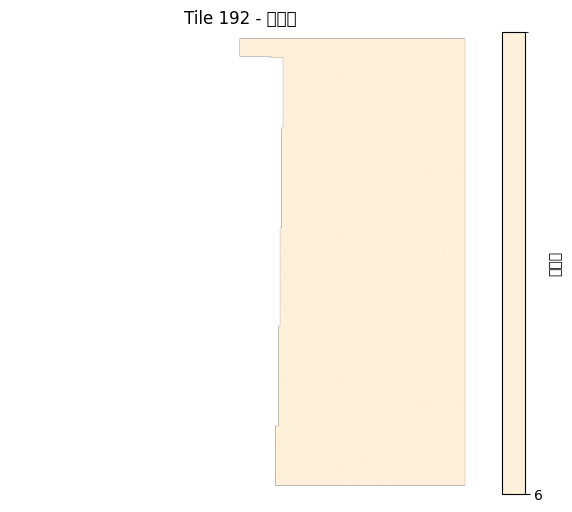

In [29]:
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np

n = 192 # 替换为你要显示的 tile ID
data = rf"D:\shanghai workshop\raster\merged_multiband\merged_tile_{n}.tif"

with rasterio.open(data) as src:
    band1 = src.read(7)

# 获取唯一值
unique_vals = np.unique(band1[~np.isnan(band1)])

# 自定义颜色映射（按需要扩展）
colors = ['#fef0d9', '#fdcc8a', '#fc8d59', '#91bfdb',  'green','#1a9850','yellow','#000000']
cmap = ListedColormap(colors[:len(unique_vals)])
norm = BoundaryNorm(np.append(unique_vals, unique_vals[-1] + 1), len(unique_vals))

# 显示图像
plt.figure(figsize=(8, 6))
plt.imshow(band1, cmap=cmap, norm=norm)
plt.colorbar(ticks=unique_vals, label='分类值')
plt.title(f"Tile {n} - 分类图")
plt.axis('off')
plt.show()

### 单元说明：显示多波段栅格的指定波段（分类波段可视化）

目的：读取指定 `merged_tile_{n}.tif`（示例中的 `n=192`），提取指定波段（示例为 band 7）并用自定义调色板显示分类图。

关键点：
- `band1 = src.read(7)`：读取第 7 波段用于分类显示；根据文件的实际波段索引调整此值。
- 使用 `np.unique` 获取分类值并为每个类别分配颜色，使用 `ListedColormap` 和 `BoundaryNorm` 控制色标显示。
- 建议：在样本上测试配色范围以确保可读性；若波段含 NaN，请先做好掩膜处理。

In [22]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject, calculate_default_transform, Resampling as WarpResampling
import numpy as np
import os

def reproject_and_resample_band(src_path, band_idx, ref_crs, ref_transform, ref_width, ref_height):
    try:
        with rasterio.open(src_path) as src:
            dst_array = np.empty((ref_height, ref_width), dtype=np.float32)

            reproject(
                source=rasterio.band(src, band_idx),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                resampling=WarpResampling.nearest
            )
            return dst_array
    except Exception as e:
        print(f"❌ 无法读取或重采样 {src_path} 第 {band_idx} 波段：{e}")
        return None

def resample_and_merge_multiband(base_raster, layers_dict, output_path):
    with rasterio.open(base_raster) as ref:
        src_crs = ref.crs
        dst_crs = rasterio.crs.CRS.from_epsg(32651)

        dst_transform, dst_width, dst_height = calculate_default_transform(
            src_crs, dst_crs, ref.width, ref.height, *ref.bounds
        )

        ref_meta = ref.meta.copy()

    dtype = np.float32
    nodata_val = np.nan
    layer_order = [
        "water",
        "park",
        "street",
        "building_height",  # 替代 building
        "building_type",
        "building_style",
        "landuse",
        "lst"
    ]
    band_count = len(layer_order)

    # 初始化为 NaN
    merged_array = np.full((band_count, dst_height, dst_width), nodata_val, dtype=dtype)

    for i, layer in enumerate(layer_order):
        path = layers_dict.get(layer)

        # building_ 开头的我们就对应不同的 band
        if layer.startswith("building_"):
            band_map = {
                "building_height": 1,
                "building_type": 2,
                "building_style": 3
            }
            band_index = band_map.get(layer, 1)
        else:
            band_index = 1

        if path and os.path.exists(path):
            print(f"📥 正在处理图层 {layer}: {path} (band {band_index})")
            arr = reproject_and_resample_band(path, band_index, dst_crs, dst_transform, dst_width, dst_height)

            if arr is not None:
                valid_mask = (~np.isnan(arr)) & (arr != 0) & (arr != 255)
                cleaned = np.full_like(arr, nodata_val)
                cleaned[valid_mask] = arr[valid_mask]
                merged_array[i] = cleaned
            else:
                print(f"⚠️ 图层 {layer} 重采样失败，保留为 NaN")
        else:
            print(f"⚠️ 图层 {layer} 缺失或路径无效：{path}")


    out_meta = ref_meta.copy()
    out_meta.update({
        "count": band_count,
        "dtype": "float32",
        "height": dst_height,
        "width": dst_width,
        "transform": dst_transform,
        "crs": dst_crs,
        "nodata": nodata_val
    })

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with rasterio.open(output_path, "w", **out_meta) as dst:
        dst.write(merged_array)
        print(f"✅ 多波段 GeoTIFF 已保存: {output_path}")

# 示例调用
n = 192
base_raster = rf"D:\shanghai workshop\raster\final_street_tiles\tile_{n}.tif"
layers = {
    "building_height": rf"D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_{n}.tif",  # band 1
    "building_type":   rf"D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_{n}.tif",  # band 2
    "building_style":  rf"D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_{n}.tif",  # band 3
    "park": rf"D:\shanghai workshop\raster\final_park_tiles\park_tile_{n}.tif",
    "water": rf"D:\shanghai workshop\raster\final_water_tiles\water_tile_{n}.tif",
    "street": rf"D:\shanghai workshop\raster\final_street_tiles\tile_{n}.tif",
    "landuse": rf"D:\shanghai workshop\raster\final_landuse_tiles\landuse_tile_{n}.tif",
    "lst": rf"D:\shanghai workshop\raster\lst\lst_tile_{n}.tif"
}
output_path = rf"D:\shanghai workshop\raster\merged_multiband\merged_tile_{n}.tif"
resample_and_merge_multiband(base_raster, layers, output_path)

📥 正在处理图层 water: D:\shanghai workshop\raster\final_water_tiles\water_tile_192.tif (band 1)
⚠️ 图层 park 缺失或路径无效：D:\shanghai workshop\raster\final_park_tiles\park_tile_192.tif
📥 正在处理图层 street: D:\shanghai workshop\raster\final_street_tiles\tile_192.tif (band 1)
📥 正在处理图层 building_height: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_192.tif (band 1)
📥 正在处理图层 building_type: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_192.tif (band 2)
📥 正在处理图层 building_style: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_192.tif (band 3)
📥 正在处理图层 landuse: D:\shanghai workshop\raster\final_landuse_tiles\landuse_tile_192.tif (band 1)
📥 正在处理图层 lst: D:\shanghai workshop\raster\lst\lst_tile_192.tif (band 1)
✅ 多波段 GeoTIFF 已保存: D:\shanghai workshop\raster\merged_multiband\merged_tile_192.tif


### 单元说明：将多源图层重投影、重采样并合并为多波段 GeoTIFF

目的：以 `base_raster` 为参考，通过 `reproject_and_resample_band` 将各图层（如 building_height、park、water、lst 等）重采样到统一网格并按固定波段顺序合并写出多波段 GeoTIFF。

输入：
- `base_raster`：参考栅格，用于确定目标 CRS/transform/尺寸
- `layers_dict`：包含图层路径的字典，键名对应 `layer_order`
- `output_path`：输出文件路径

输出：多波段 GeoTIFF（`nodata` = NaN），波段顺序由 `layer_order` 决定。

关键点：
- `building_*` 前缀的图层会映射到不同的 band 索引（height/type/style）。
- 若某层缺失或重采样失败，则该波段以 NaN 填充。
- 建议：先在少量 tile 上验证路径和波段映射，之后再批量运行以避免中途失败。

📊 波段数量: 8
📐 尺寸 (宽, 高): 308 308
🗺️ 投影: EPSG:32651
📏 分辨率: (0.8525842711205176, 0.8525842711205176)
📦 数据类型: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
🟢 Band 1 的最小值: nan, 最大值: nan


C:\Users\owner\AppData\Local\Temp\ipykernel_40028\3699557589.py:18: RuntimeWarning: All-NaN slice encountered
  print(f"🟢 Band {i} 的最小值: {np.nanmin(band)}, 最大值: {np.nanmax(band)}")


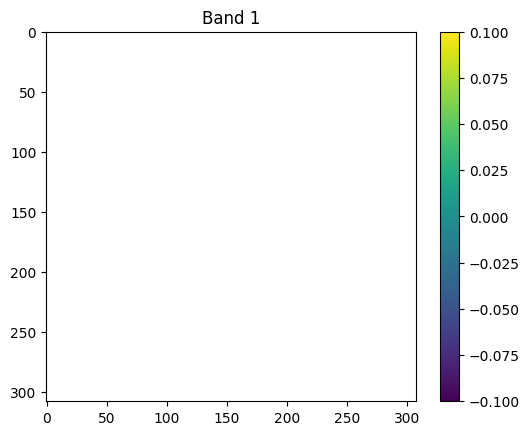

🟢 Band 2 的最小值: nan, 最大值: nan


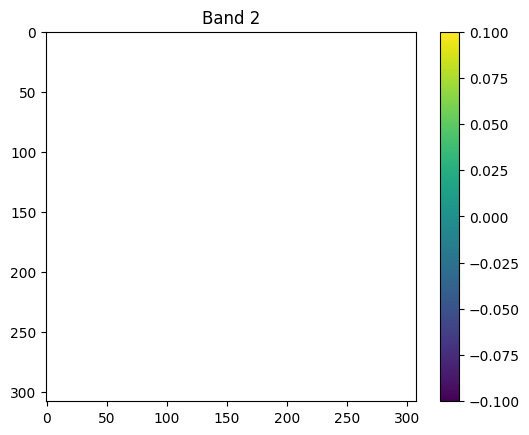

🟢 Band 3 的最小值: 2.0, 最大值: 2.0


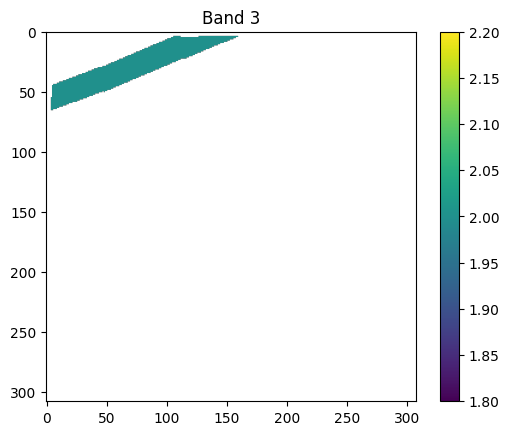

🟢 Band 4 的最小值: 8.15768814086914, 最大值: 38.251502990722656


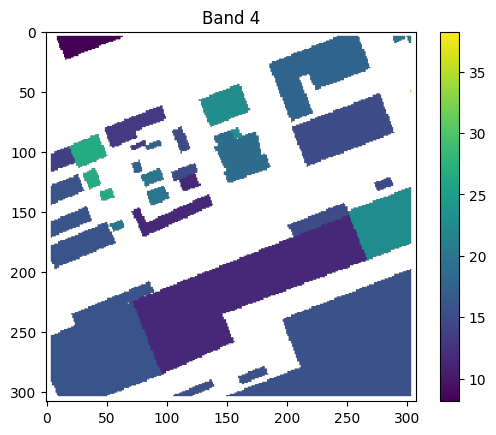

🟢 Band 5 的最小值: 3.0, 最大值: 3.0


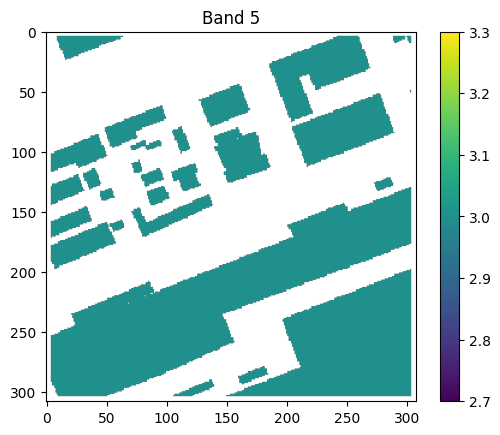

🟢 Band 6 的最小值: 2.0, 最大值: 2.0


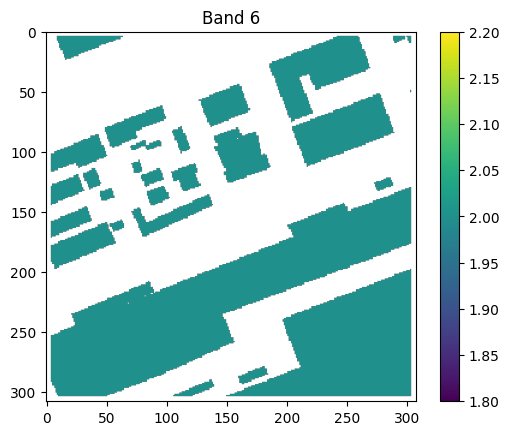

🟢 Band 7 的最小值: 6.0, 最大值: 7.0


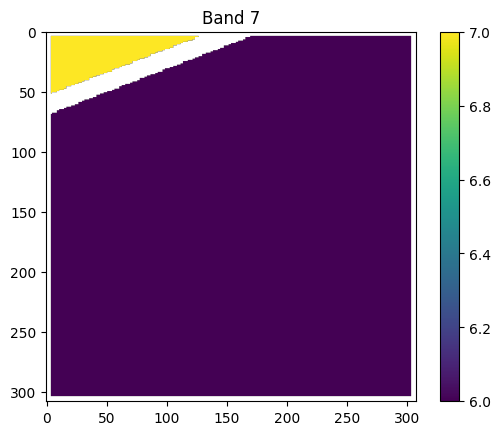

🟢 Band 8 的最小值: -9999.0, 最大值: 55.22768783569336


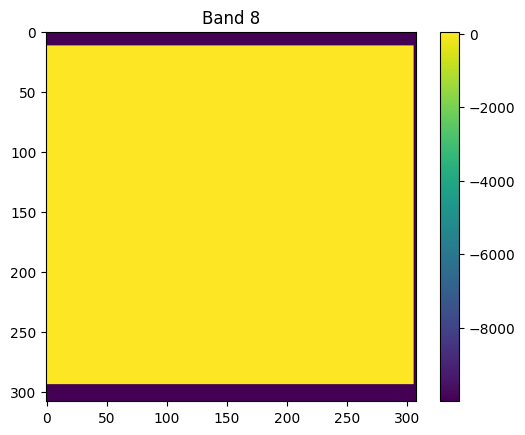

In [33]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# 文件路径
file_path = r"D:\shanghai workshop\raster\visual\merged_tile_51738.tif"

# 读取文件
with rasterio.open(file_path) as src:

    for i in range(1, src.count + 1):
        band = src.read(i)

        # 可选：显示图像（小图）
        plt.imshow(band, cmap="viridis")
        plt.title(f"Band {i}")
        plt.colorbar()
        plt.show()


### 单元说明：逐波段显示合并后的多波段栅格（快速检查）

目的：读取 `merged_tile_51738.tif`（示例）并逐波段展示（使用 `plt.imshow`），便于快速检查各波段的视觉表现。

关键点：
- 循环 `for i in range(1, src.count + 1)` 逐波段读取并显示；注意对 nodata 值的处理需要根据实际文件调整。
- 建议：此单元适合交互式调试，若需要保存图片可将 `plt.savefig(...)` 加入循环中。

In [39]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os
import numpy as np

def rasterize_multiple_fields_to_multiband(shapefile_path, grid_path, class_fields, output_dir, resolution=10, nodata=255, start_id=0):
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    if not gdf.crs.is_projected:
        gdf = gdf.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(epsg=32651)
    if gdf.crs != grid.crs:
        grid = grid.to_crs(gdf.crs)

    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_dir, exist_ok=True)

    # ✅ 第一步：提前为所有字段生成全局映射字典
    field_maps = {}
    for field in class_fields:
        if field not in gdf.columns:
            raise ValueError(f"字段 {field} 不存在于 shapefile 中")
        if gdf[field].dtype.kind in ['O', 'U']:  # 字符型
            unique_vals = sorted(gdf[field].dropna().unique())
            val_map = {v: i+1 for i, v in enumerate(unique_vals)}
            print(f"字段 {field} 的映射：{val_map}")
            field_maps[field] = val_map
            gdf[f"__mapped_{field}"] = gdf[field].map(val_map).fillna(0).astype(int)
        else:
            gdf[f"__mapped_{field}"] = gdf[field].fillna(0)

    for idx, cell in grid.iterrows():
        tile_id = cell["ID"]

        # ✅ 跳过起始 ID 之前的 tile
        if tile_id < start_id:
            continue

        out_path = os.path.join(output_dir, f"building_tile_{tile_id}.tif")

        if os.path.exists(out_path):
            print(f"⏩ 已存在，跳过: {out_path}")
            continue

        grid_geom = cell.geometry
        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")
        if clipped.empty:
            continue

        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        bands = []

        for field in class_fields:
            mapped_col = f"__mapped_{field}"
            class_vals = clipped[mapped_col]
            shapes = [(geom, val) for geom, val in zip(clipped.geometry, class_vals)]

            raster = rasterize(
                shapes=shapes,
                out_shape=(height, width),
                transform=transform,
                fill=nodata,
                dtype='uint8' if class_vals.dtype == int else 'float32'
            )
            bands.append(raster)

        bands_array = np.stack(bands, axis=0)

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=len(class_fields),
            dtype=bands_array.dtype,
            crs=gdf.crs,
            transform=transform,
            nodata=nodata
        ) as dst:
            dst.write(bands_array)

        print(f"✅ 输出: {out_path}")

rasterize_multiple_fields_to_multiband(
    shapefile_path=r'D:\shanghai workshop\vector\Building_processed nearest 1 to 500m_finver\result\building_UTM51N.shp',
    grid_path=r"D:\shanghai workshop\vector\shanghai_grid_256m_clipped.shp",
    class_fields=["Height", "Function", "Style"],
    output_dir=r"D:\shanghai workshop\raster\final_building_tiles_with_bands",
    resolution=1,
    nodata=255,
    start_id=1000
)


字段 Function 的映射：{'Business': 1, 'Industry': 2, 'Office': 3, 'Other': 4, 'Public service': 5, 'Residence': 6}
字段 Style 的映射：{'M': 1, 'Modern': 2, 'Postmodern': 3, 'Traditional': 4}
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3636.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3637.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3638.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3639.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3640.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3978.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3979.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\building_tile_3980.tif
⏩ 已存在，跳过: D:\shanghai workshop\raster\final_building_tiles_with_bands\buildin

### 单元说明：将矢量要素的多个字段栅格化为多波段（每格一文件）

目的：对 `shapefile_path` 中的若干字段（如 Height、Function、Style）进行映射并分别栅格化，最终将这些波段写入同一多波段 GeoTIFF（每个网格输出一个文件）。

输入/输出与关键点：
- `class_fields`：字段名列表；字符型字段会自动映射为整数编号（从 1 开始，0 为背景）。
- 输出：`building_tile_{ID}.tif`，波段数量等于 `len(class_fields)`。
- 建议：调用前检查 shapefile 字段是否存在，确认 `start_id` 参数用于跳过已处理或不需要的 tile。

In [38]:
import os

folder_with_bands = r"D:\shanghai workshop\raster\final_building_tiles_with_bands"
folder_standard = r"D:\shanghai workshop\raster\final_building_tiles"

# 获取两个文件夹中的 .tif 文件名（不含路径）
files_with_bands = set(f for f in os.listdir(folder_with_bands) if f.endswith(".tif"))
files_standard = set(f for f in os.listdir(folder_standard) if f.endswith(".tif"))

# 找出标准版本中存在但多波段版本中缺失的文件
missing_files = sorted(files_standard - files_with_bands)

print(f"❌ 在带波段文件夹中缺失的文件有 {len(missing_files)} 个：")
for f in missing_files:
    print("   -", f)


❌ 在带波段文件夹中缺失的文件有 14214 个：
   - building_tile_100224.tif
   - building_tile_100225.tif
   - building_tile_100226.tif
   - building_tile_100227.tif
   - building_tile_100228.tif
   - building_tile_100235.tif
   - building_tile_100236.tif
   - building_tile_100237.tif
   - building_tile_100238.tif
   - building_tile_100239.tif
   - building_tile_100242.tif
   - building_tile_100244.tif
   - building_tile_100245.tif
   - building_tile_100246.tif
   - building_tile_100247.tif
   - building_tile_100248.tif
   - building_tile_100249.tif
   - building_tile_100250.tif
   - building_tile_100253.tif
   - building_tile_100254.tif
   - building_tile_100255.tif
   - building_tile_100256.tif
   - building_tile_100257.tif
   - building_tile_100258.tif
   - building_tile_100259.tif
   - building_tile_100260.tif
   - building_tile_100261.tif
   - building_tile_100262.tif
   - building_tile_100263.tif
   - building_tile_100264.tif
   - building_tile_100265.tif
   - building_tile_100266.tif
   - building_

### 单元说明：比较文件夹以找出缺失的多波段文件

目的：比较 `folder_with_bands`（带波段版本）与 `folder_standard`（标准版本）中的 `.tif` 文件名，找出在带波段文件夹中缺失的文件列表，便于补齐或排查原因。

关键点：
- 输出：打印缺失文件数量与文件名列表。
- 建议：在补齐缺失文件时注意文件命名一致性与路径正确性。